In [1]:
!git clone https://github.com/Ahmed-AlTahan/CNN-LIME.git /content/thesis
%cd /content/thesis

Cloning into '/content/thesis'...
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 7 (delta 0), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (7/7), 6.95 KiB | 2.32 MiB/s, done.
/content/thesis


In [5]:
!pip -q install gdown
!gdown --fuzzy "https://drive.google.com/file/d/1OfQmMsNR5DDLbZUmLL2DGuHPIGFxnqy6/view?usp=drive_link" -O data.zip
!mkdir -p data
!unzip -q data.zip -d data

Downloading...
From (original): https://drive.google.com/uc?id=1OfQmMsNR5DDLbZUmLL2DGuHPIGFxnqy6
From (redirected): https://drive.google.com/uc?id=1OfQmMsNR5DDLbZUmLL2DGuHPIGFxnqy6&confirm=t&uuid=f34aadc1-ef2f-4499-94d8-04d361924dc5
To: /content/thesis/data.zip
100% 1.44G/1.44G [00:23<00:00, 60.2MB/s]
15workpieces_same_position/sorted_by_station/Station1/1_weißTabelle.xlsx:  mismatching "local" filename (15workpieces_same_position/sorted_by_station/Station1/1_wei├ЯTabelle.xlsx),
         continuing with "central" filename version
15workpieces_same_position/sorted_by_station/Station2/1_weißTabelle.xlsx:  mismatching "local" filename (15workpieces_same_position/sorted_by_station/Station2/1_wei├ЯTabelle.xlsx),
         continuing with "central" filename version
15workpieces_same_position/sorted_by_station/Station3/1_weißTabelle.xlsx:  mismatching "local" filename (15workpieces_same_position/sorted_by_station/Station3/1_wei├ЯTabelle.xlsx),
         continuing with "central" filename versio

In [6]:
!ls data/15workpieces_same_position/all_images | head
!ls data/15workpieces_same_position/all_images/*.jpg | wc -l

2024-04-11-100550.jpg
2024-04-11-100550.txt
2024-04-11-100600.jpg
2024-04-11-100600.txt
2024-04-11-100615.jpg
2024-04-11-100615.txt
2024-04-11-100626.jpg
2024-04-11-100626.txt
2024-04-11-100638.jpg
2024-04-11-100638.txt
2490


In [7]:
!python -c "from dataset import SimpleFischertechnikDataset as D; import config; D.check_scene_grouping(config.IMAGE_DIR)"

Scene check: 166 blocks, 0 suspicious.


In [8]:
!python -u train.py

Using device: cuda
Scene check: 166 blocks, 0 suspicious.
Scenes   -> train: 116 | val: 25 | test: 25
Images   -> train: 1740 | val: 375 | test: 375
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 177MB/s] 

Starting training loop...
Epoch [1/100] | Train Loss: 2.9248 | Train Acc: 5.86% | Val Acc: 7.73%
   ---> New best validation accuracy! Weights saved.
Epoch [2/100] | Train Loss: 2.6896 | Train Acc: 10.69% | Val Acc: 18.40%
   ---> New best validation accuracy! Weights saved.
Epoch [3/100] | Train Loss: 2.2659 | Train Acc: 24.25% | Val Acc: 33.07%
   ---> New best validation accuracy! Weights saved.
Epoch [4/100] | Train Loss: 1.8811 | Train Acc: 38.85% | Val Acc: 46.93%
   ---> New best validation accuracy! Weights saved.
Epoch [5/100] | Train Loss: 1.5070 | Train Acc: 53.39% | Val Acc: 60.53%
   ---> New best validation accuracy! Weights saved.
Epoch [6/100] | Train 

In [12]:
%cd /content/thesis
!python evaluate.py

/content/thesis
Using device: cuda | evaluating split: 'test'
Loaded 375 samples from 25 scenes.

Overall test accuracy: 80.53%

              precision    recall  f1-score   support

           0     0.7419    0.9200    0.8214        25
           1     0.7727    0.6800    0.7234        25
           2     0.7407    0.8000    0.7692        25
           3     0.8235    0.5600    0.6667        25
           4     0.8889    0.9600    0.9231        25
           5     1.0000    0.8400    0.9130        25
           6     0.9130    0.8400    0.8750        25
           7     0.9091    0.8000    0.8511        25
           8     0.9500    0.7600    0.8444        25
           9     1.0000    0.7600    0.8636        25
          10     1.0000    0.9200    0.9583        25
          11     1.0000    0.7200    0.8372        25
          12     0.4615    0.9600    0.6234        25
          13     0.6176    0.8400    0.7119        25
          14     0.9474    0.7200    0.8182        25

    a

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
!mkdir -p "/content/drive/MyDrive/thesis_results"
!cp /content/thesis/confusion_matrix_15x15_test.png "/content/drive/MyDrive/thesis_results/"
!cp /content/thesis/sample_predictions_grid_test.png "/content/drive/MyDrive/thesis_results/"
!cp /content/thesis/predictions_test.csv "/content/drive/MyDrive/thesis_results/"
!cp /content/thesis/fischertechnik_cnn.pth "/content/drive/MyDrive/thesis_results/"
!ls -lh "/content/drive/MyDrive/thesis_results/"

total 57M
-rw------- 1 root root 242K Nov  8 13:45 confusion_matrix_15x15_test.png
-rw------- 1 root root  43M Nov  8 13:45 fischertechnik_cnn.pth
-rw------- 1 root root  28K Nov  8 13:45 predictions_test.csv
-rw------- 1 root root  14M Nov  8 13:45 sample_predictions_grid_test.png


In [15]:
drive.flush_and_unmount()

/content/thesis


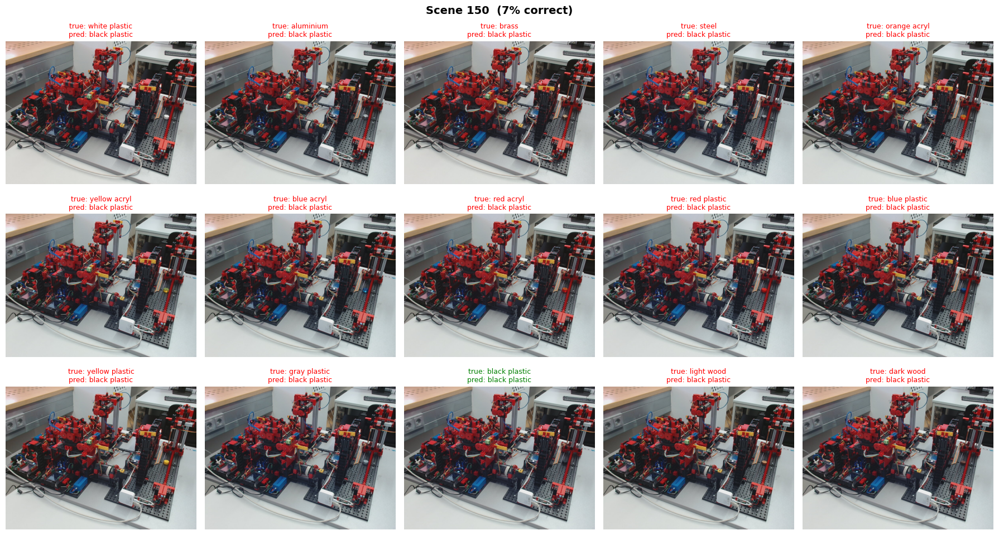

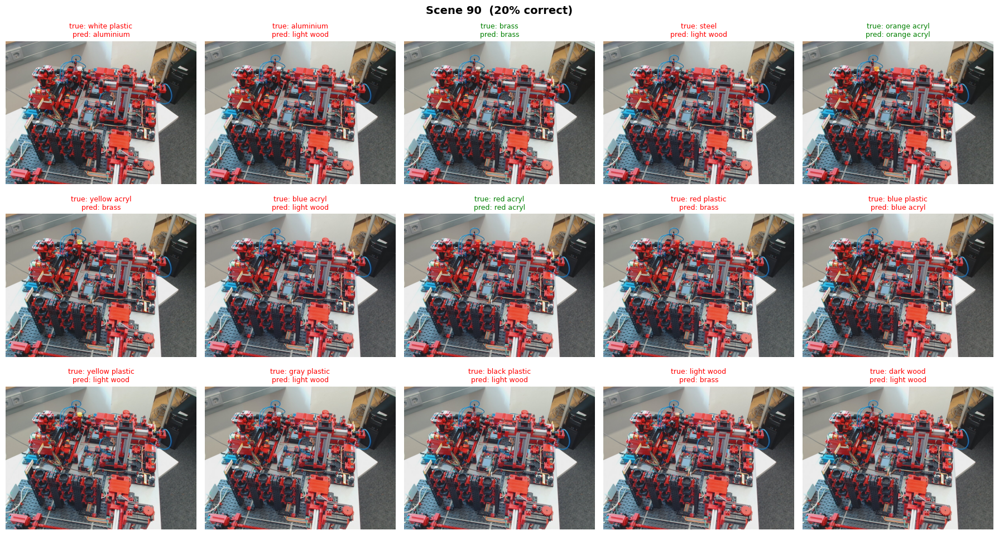

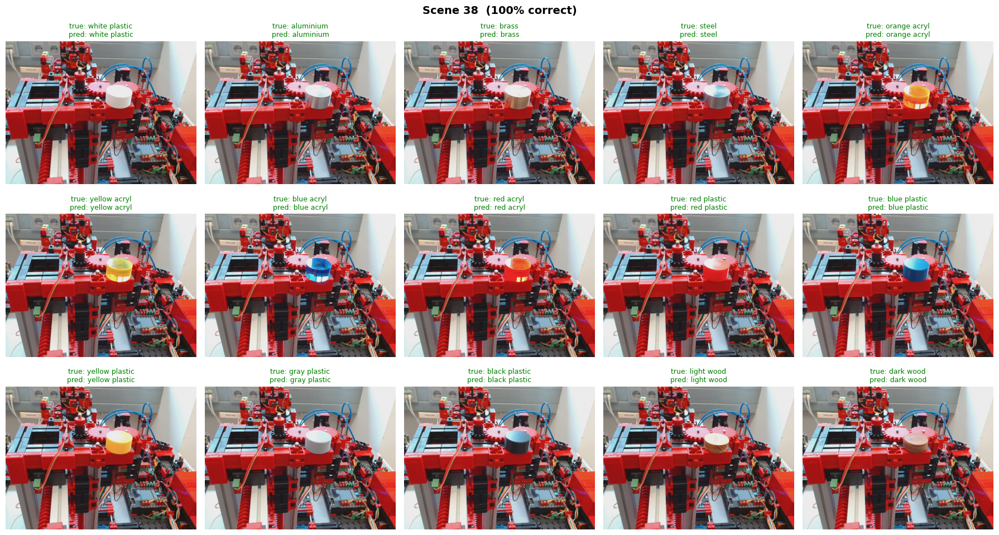

In [16]:
%cd /content/thesis
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

names = ["white plastic","aluminium","brass","steel","orange acryl","yellow acryl",
         "blue acryl","red acryl","red plastic","blue plastic","yellow plastic",
         "gray plastic","black plastic","light wood","dark wood"]

df = pd.read_csv("predictions_test.csv")
df["ok"] = df.true == df.pred
best_scene = df.groupby("scene").ok.mean().idxmax()   # a scene with 100% accuracy

def show_scene(s):
    d = df[df.scene == s].sort_values("true")
    fig, axes = plt.subplots(3, 5, figsize=(18, 10))
    for ax, (_, r) in zip(axes.flatten(), d.iterrows()):
        ax.imshow(Image.open(r.img_path)); ax.axis("off")
        ax.set_title(f"true: {names[r.true]}\npred: {names[r.pred]}", fontsize=9,
                     color="green" if r.ok else "red")
    acc = d.ok.mean() * 100
    plt.suptitle(f"Scene {s}  ({acc:.0f}% correct)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"scene_{s}.png", dpi=150)
    plt.show()

for s in (150, 90, best_scene):
    show_scene(s)

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
!mkdir -p "/content/drive/MyDrive/thesis_results"
!cp /content/thesis/scene_*.png "/content/drive/MyDrive/thesis_results/"
!ls -lh "/content/drive/MyDrive/thesis_results/"

total 73M
-rw------- 1 root root 242K Nov  8 13:45 confusion_matrix_15x15_test.png
-rw------- 1 root root  43M Nov  8 13:45 fischertechnik_cnn.pth
-rw------- 1 root root  28K Nov  8 13:45 predictions_test.csv
-rw------- 1 root root  14M Nov  8 13:45 sample_predictions_grid_test.png
-rw------- 1 root root 5.1M Nov  8 14:00 scene_150.png
-rw------- 1 root root 4.9M Nov  8 14:00 scene_38.png
-rw------- 1 root root 5.6M Nov  8 14:00 scene_90.png


In [19]:
drive.flush_and_unmount()